<a href="https://colab.research.google.com/github/RichardEager0803/Machine-Learning/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Assignment #7**

Unsupervised Chemical Segmentation on the Wine Recognition Dataset

**Goals:**

* Examine unsupervised learning algorithms such as **K-Means Clustering, DBSCAN, and HDBSCAN** using the classic **Wine Recognition dataset**
* Perform exploratory data analysis and apply feature scaling
* Evaluate optimal cluster counts using the Elbow Method and Silhouette scores
* Visualize Voronoi decision boundaries
* Explore soft clustering distance transformations
* Implement density-based clustering techniques
* Evaluate how well centroid-based and density-based clustering algorithms recover the underlying natural groupings in high-dimensional chemical feature spaces without using class labels during model fitting

Imports:

In [10]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances
from sklearn.cluster import DBSCAN
import hdbscan
from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, silhouette_score
import warnings

Task 1:
* Outputs the dataset dimensions, feature statistics, and missinge value checks
* Standardizes all 13 features and displays a comparison of feature distributions before and after scaling

In [11]:
# Loads the wine dataset
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

# Dataset dimensions
print("Dataset Shape (Samples, Features):", X.shape)
print("Target Classes:", wine.target_names)

print("\nClass Distribution:")
print(pd.Series(y).value_counts().sort_index())

# Summary statistics
print("\nSummary Statistics")
print(X.describe())

# Missing value check
print("\nMissing Values:")
print(X.isnull().sum())

# Standardizes all 13 features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

# Compares distributions before and after scaling
comparison = pd.concat(
    [
        X.describe().add_suffix('_Original'),
        X_scaled.describe().add_suffix('_Scaled')
    ],
    axis=1
)

print("\nFeature Distributions Before and After Scaling:")
print(comparison)

print("\nFirst Five Rows:")
display(X.head())

print("\nFirst Five Scaled Rows:")
display(X_scaled.head())


Dataset Shape (Samples, Features): (178, 13)
Target Classes: ['class_0' 'class_1' 'class_2']

Class Distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64

Summary Statistics
          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.0

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



First Five Scaled Rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


Task 2:
* Iterates k from 1 to 10 for K-Means clustering on the scaled features
* Computes and plots side-by-side:
>1. The Elbow Method curve
>2. The Silhouette Scores curve for k in [2, 10]
* The optimal k value suggested by both metrics is shown below

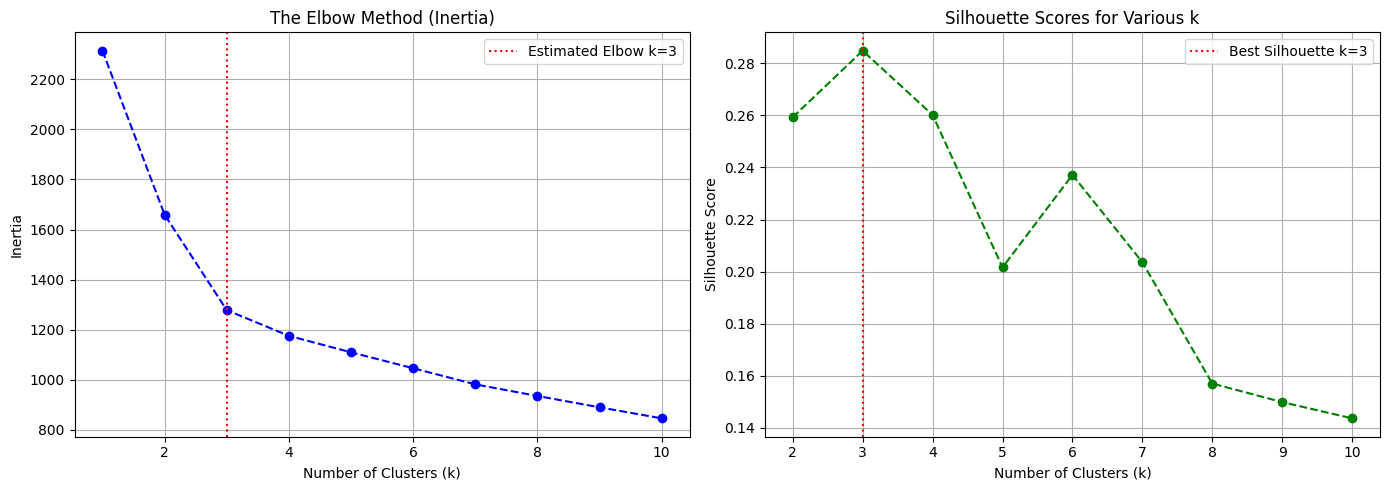

Optimal k suggested by Elbow Method: 3
Optimal k suggested by Silhouette Method: 3
Both methods suggest k = 3


In [12]:
# Result storage
inertia = []
silhouette_scores = []

# Elbow Method
for k in range(1, 11):
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  inertia.append(kmeans.inertia_)

# Silhouette Method
for k in range(2, 11):
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(X_scaled)
  silhouette_scores.append(silhouette_score(X_scaled, labels))

# Estimates the elbow using maximum distance from the endpoint line
x_vals = np.array(list(range(1, 11)))
y_vals = np.array(inertia)

# Normalizes both axes
x_norm = (x_vals - x_vals.min()) / (x_vals.max() - x_vals.min())
y_norm = (y_vals - y_vals.min()) / (y_vals.max() - y_vals.min())

# Distance from straight line connecting endpoints
distances = np.abs(
    (y_norm[-1] - y_norm[0]) * x_norm
    - (x_norm[-1] - x_norm[0]) * y_norm
    + x_norm[-1] * y_norm[0]
    - y_norm[-1] * x_norm[0]
) / np.sqrt(
    (y_norm[-1] - y_norm[0])**2
    + (x_norm[-1] - x_norm[0])**2
)

elbow_k = x_vals[np.argmax(distances)]

# Best Silhouette Score
silhouette_k = np.argmax(silhouette_scores) + 2

# Plots both methods side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow curve
axes[0].plot(
    x_vals,
    inertia,
    marker='o',
    linestyle='--',
    color='blue'
)

axes[0].axvline(
    elbow_k,
    color='red',
    linestyle=':',
    label=f'Estimated Elbow k={elbow_k}'
)

axes[0].set_title('The Elbow Method (Inertia)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].legend()
axes[0].grid(True)

# Silhouette curve
axes[1].plot(
    range(2, 11),
    silhouette_scores,
    marker='o',
    linestyle='--',
    color='green'
)

axes[1].axvline(
    silhouette_k,
    color='red',
    linestyle=':',
    label=f'Best Silhouette k={silhouette_k}'
)

axes[1].set_title('Silhouette Scores for Various k')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Optimal k suggested by Elbow Method:", elbow_k)
print("Optimal k suggested by Silhouette Method:", silhouette_k)

if elbow_k == silhouette_k:
    print("Both methods suggest k =", elbow_k)
else:
    print("The two methods suggest different values of k.")

Task 3:
* Applies PCA strictly to reduce the 13 scaled features down to two principal components for visualization purposes
* We fit a K-Means model (k=3) on the two dimensional projected space
* The decision boundaries are plotted below using the Voronoi method

Original Dimensions: (178, 13)
PCA Dimensions: (178, 2)

Explained Variance Ratio:  [0.36198848 0.1920749 ]

Total Explained Variance:  0.5540633835693527


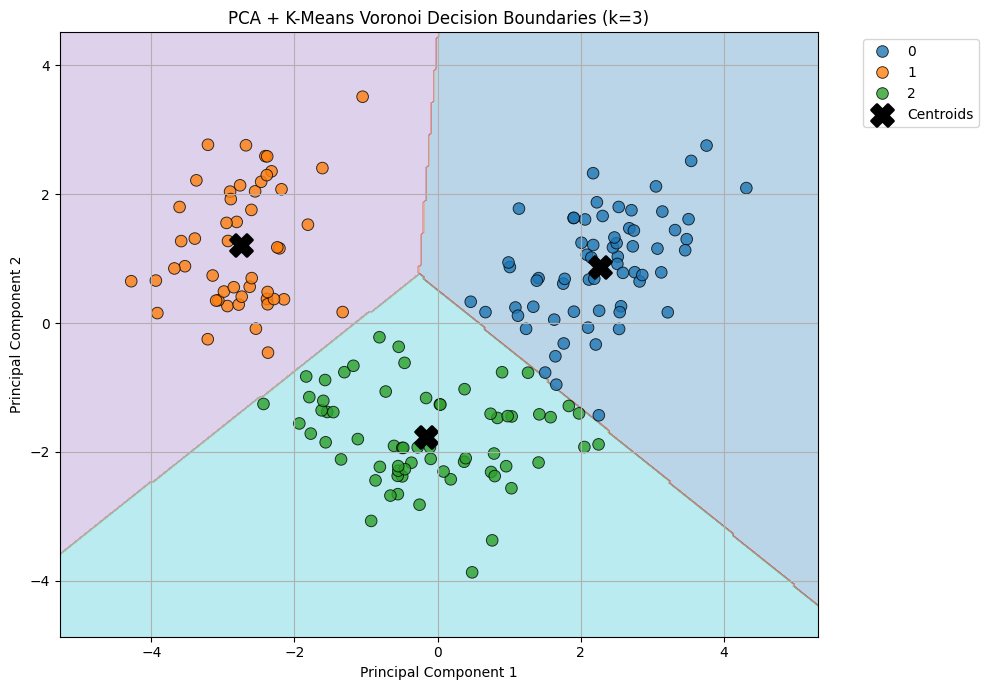

In [13]:
# Applies PCA to reduce 13 features to 2 components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Dimensions:", X_scaled.shape)
print("PCA Dimensions:", X_pca.shape)

print("\nExplained Variance Ratio: ", pca.explained_variance_ratio_)
print("\nTotal Explained Variance: ", sum(pca.explained_variance_ratio_))

# Fits K-Means on 2D PCA data
k = 3
kmeans_pca = KMeans(n_clusters=k, random_state=42, n_init=10)
pca_labels = kmeans_pca.fit_predict(X_pca)

# Extracts centroids
centroids_pca = kmeans_pca.cluster_centers_

# Creates mesh grid
x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

# Predicts cluster labels for mesh points
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = kmeans_pca.predict(grid_points)
Z = Z.reshape(xx.shape)

# Plots decision boundaries
plt.figure(figsize=(10, 7))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='tab10')

# Plots PCA data points
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=pca_labels,
    palette='tab10',
    s=70,
    alpha=0.8,
    edgecolor='k'
)

# Plots centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker='X',
    s=250,
    linewidths=2,
    color='black',
    label='Centroids'
)

plt.title('PCA + K-Means Voronoi Decision Boundaries (k=3)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

Task 4:
* Selects 5 representative wine samples from the dataset
* Using the fitted 13-feature K-Means model (k=3), the distance matrix is then computed and displayed
* Generates and displays a heatmap visualizing the soft clustering distance profiles across all 3 cluster centroids, highlighting the minimum distance corresponding to each sample's hard cluster assignment



Distance Matrix (5 Samples x 3 Centroids):
                 Cluster 0  Cluster 1  Cluster 2
Wine Sample 0        4.963      6.293      2.063
Wine Sample 35       2.941      4.872      1.401
Wine Sample 70       2.977      3.259      4.837
Wine Sample 105      3.066      4.062      5.437
Wine Sample 177      5.776      2.557      6.072

Hard Cluster Assignments:
Wine Sample 0: Cluster 2
Wine Sample 35: Cluster 2
Wine Sample 70: Cluster 0
Wine Sample 105: Cluster 0
Wine Sample 177: Cluster 1


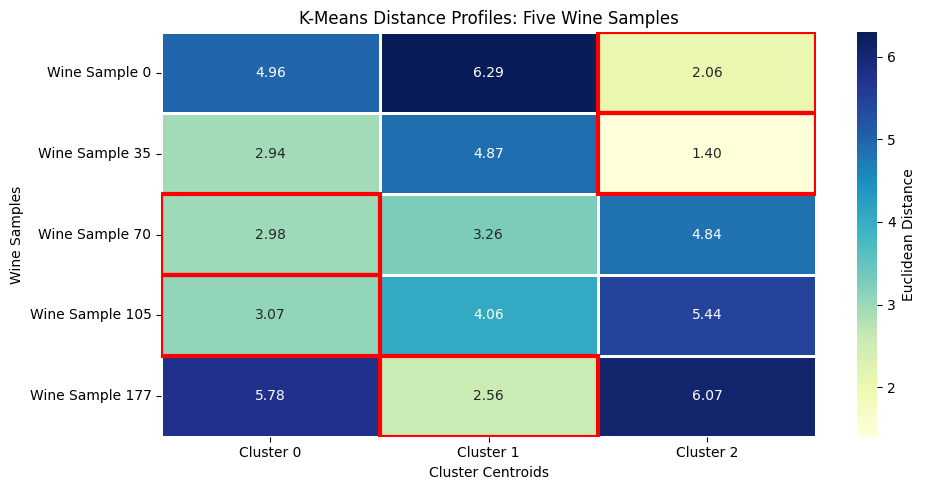

In [14]:
# Fits K-Means on all 13 standard features
kmeans_13 = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_labels = kmeans_13.fit_predict(X_scaled)

# Select five representative samples
sample_indices = [0, 35, 70, 105, 177]

representative_samples = X_scaled.iloc[sample_indices]

# Calculates the distances to all three centroids
distance_matrix = pairwise_distances(
    representative_samples,
    kmeans_13.cluster_centers_,
    metric='euclidean'
)

# Distance DataFrame
distance_df = pd.DataFrame(
    distance_matrix,
    index=[f'Wine Sample {i}' for i in sample_indices],
    columns=['Cluster 0', 'Cluster 1', 'Cluster 2']
)

print("Distance Matrix (5 Samples x 3 Centroids):")
print(distance_df.round(3))

# Identifies the nearest centroid for each sample
nearest_clusters = np.argmin(distance_matrix, axis=1)

print("\nHard Cluster Assignments:")
for i, cluster in enumerate(nearest_clusters):
    print(f"Wine Sample {sample_indices[i]}: Cluster {cluster}")

# Plots the heatmap
plt.figure(figsize=(10, 5))
ax = sns.heatmap(
    distance_df,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=1,
    cbar_kws={'label': 'Euclidean Distance'}
)

# Highlights minimum distance in each row
for row in range(len(distance_matrix)):
    col = nearest_clusters[row]
    ax.add_patch(plt.Rectangle((col, row), 1, 1, fill=False, edgecolor='red', linewidth=3))

plt.title('K-Means Distance Profiles: Five Wine Samples')
plt.xlabel('Cluster Centroids')
plt.ylabel('Wine Samples')
plt.tight_layout()
plt.show()



Task 5:
* We fit a DBSCAN model on the 13-dimensional scaled feature space
* We then experiment with the two hyperparameter settings, the (epsilon, and minimum samples)
* Outputs and shows the number of identified clusters and noise points
* Visualizes the DBSCAN assignments on the 2D PCA projection space, clearly distinguishing noise points from core cluster members


DBSCAN Configuration 1
Parameters: {'eps': 1.6, 'min_samples': 5}
Number of Clusters: 3
Number of Noise Points: 162

DBSCAN Configuration 2
Parameters: {'eps': 2.1, 'min_samples': 5}
Number of Clusters: 3
Number of Noise Points: 62

DBSCAN Configuration 3
Parameters: {'eps': 2.4, 'min_samples': 5}
Number of Clusters: 2
Number of Noise Points: 36

DBSCAN Configuration 4
Parameters: {'eps': 2.9, 'min_samples': 5}
Number of Clusters: 1
Number of Noise Points: 12

DBSCAN Configuration 5
Parameters: {'eps': 1.6, 'min_samples': 6}
Number of Clusters: 1
Number of Noise Points: 172

DBSCAN Configuration 6
Parameters: {'eps': 2.1, 'min_samples': 6}
Number of Clusters: 3
Number of Noise Points: 70

DBSCAN Configuration 7
Parameters: {'eps': 2.4, 'min_samples': 6}
Number of Clusters: 2
Number of Noise Points: 39

DBSCAN Configuration 8
Parameters: {'eps': 2.9, 'min_samples': 6}
Number of Clusters: 1
Number of Noise Points: 12


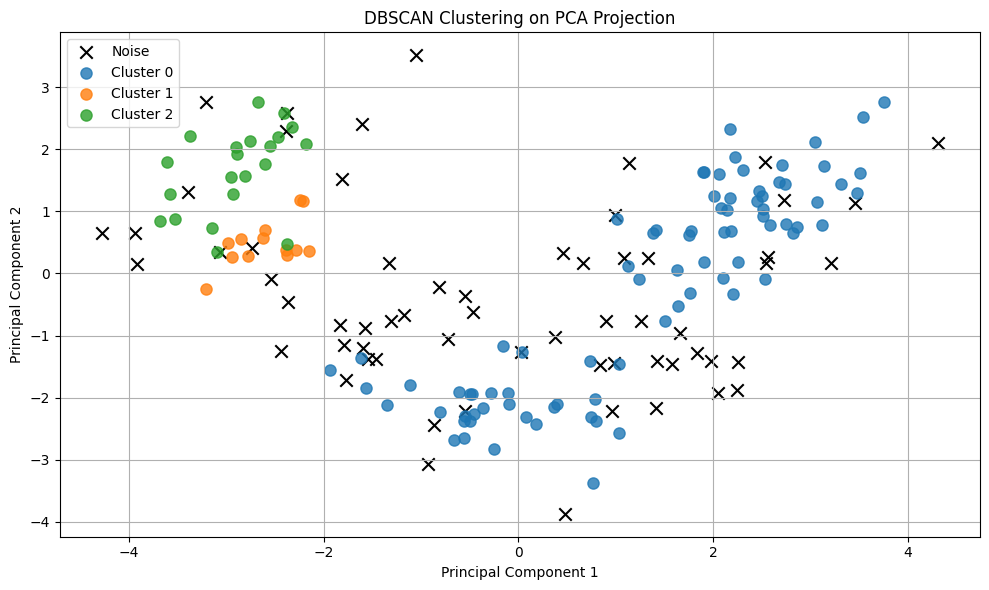

In [15]:
# Two DBSCAN configurations
dbscan_configs = [
    {'eps': 1.6, 'min_samples': 5},
    {'eps': 2.1, 'min_samples': 5},
    {'eps': 2.4, 'min_samples': 5},
    {'eps': 2.9, 'min_samples': 5},
    {'eps': 1.6, 'min_samples': 6},
    {'eps': 2.1, 'min_samples': 6},
    {'eps': 2.4, 'min_samples': 6},
    {'eps': 2.9, 'min_samples': 6},
]

dbscan_results = {}

for i, params in enumerate(dbscan_configs, start=1):
    dbscan = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = dbscan.fit_predict(X_scaled)
    dbscan_results[i] = labels

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)

    print(f"\nDBSCAN Configuration {i}")
    print("Parameters:", params)
    print("Number of Clusters:", n_clusters)
    print("Number of Noise Points:", n_noise)

# Selects one of the configurations for visualization purposes
dbscan_labels = dbscan_results[2]

# Visualizes on PCA projection
plt.figure(figsize=(10, 6))

# Plots each cluster and noise separately
unique_labels = sorted(set(dbscan_labels))

for label in unique_labels:
    mask = dbscan_labels == label

    if label == -1:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            c='black',
            marker='x',
            s=80,
            label='Noise'
        )

    else:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            s=65,
            alpha=0.8,
            label=f'Cluster {label}'
        )

plt.title('DBSCAN Clustering on PCA Projection')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Task 6:
* Fits an HDBSCAN model using min_cluster_size=5 or min_samples=5 on the 13-dimensional scaled feature space
* Prints the total number of clusters discovered and noise points detected
* Visualizes the resulting HDBSCAN cluster assignments on the 2D PCA projection space

HDBSCAN Results
Number of Clusters: 2
Number of Noise Points: 70


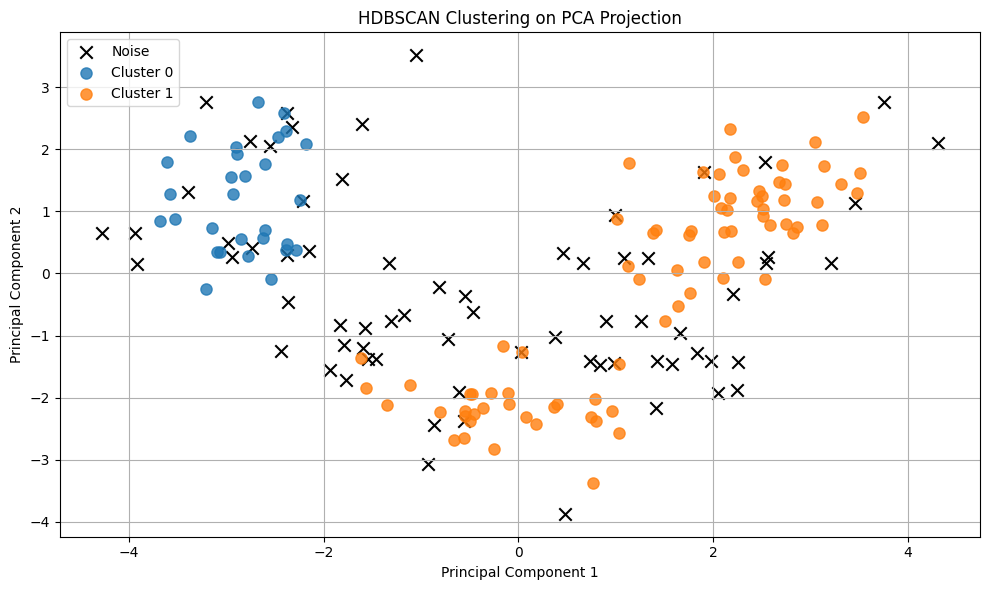

In [16]:
# Fits HDBSCAN on the 13-dimensional standardized data
hdbscan_model = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=5)
hdbscan_labels = hdbscan_model.fit_predict(X_scaled)

# Counts clusters and noise
n_clusters_hdbscan = len(set(hdbscan_labels) - {-1})
n_noise_hdbscan = list(hdbscan_labels).count(-1)

print("HDBSCAN Results")
print("Number of Clusters:", n_clusters_hdbscan)
print("Number of Noise Points:", n_noise_hdbscan)

plt.figure(figsize=(10, 6))

unique_labels = sorted(set(hdbscan_labels))

for label in unique_labels:
    mask = hdbscan_labels == label

    if label == -1:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            c='black',
            marker='x',
            s=80,
            label='Noise',
        )
    else:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            s=65,
            alpha=0.8,
            label=f'Cluster {label}',
        )

plt.title('HDBSCAN Clustering on PCA Projection')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Task 7:

* Computes a single-linkage hierarachical clustering matrix on the scaled Wine features
* Plots a hierarchical clustering dendrogram to visualize how individual chemical profiles merge across distance thresholds, connecting the visual structure to HDBSCAN's stability extraction mechanism

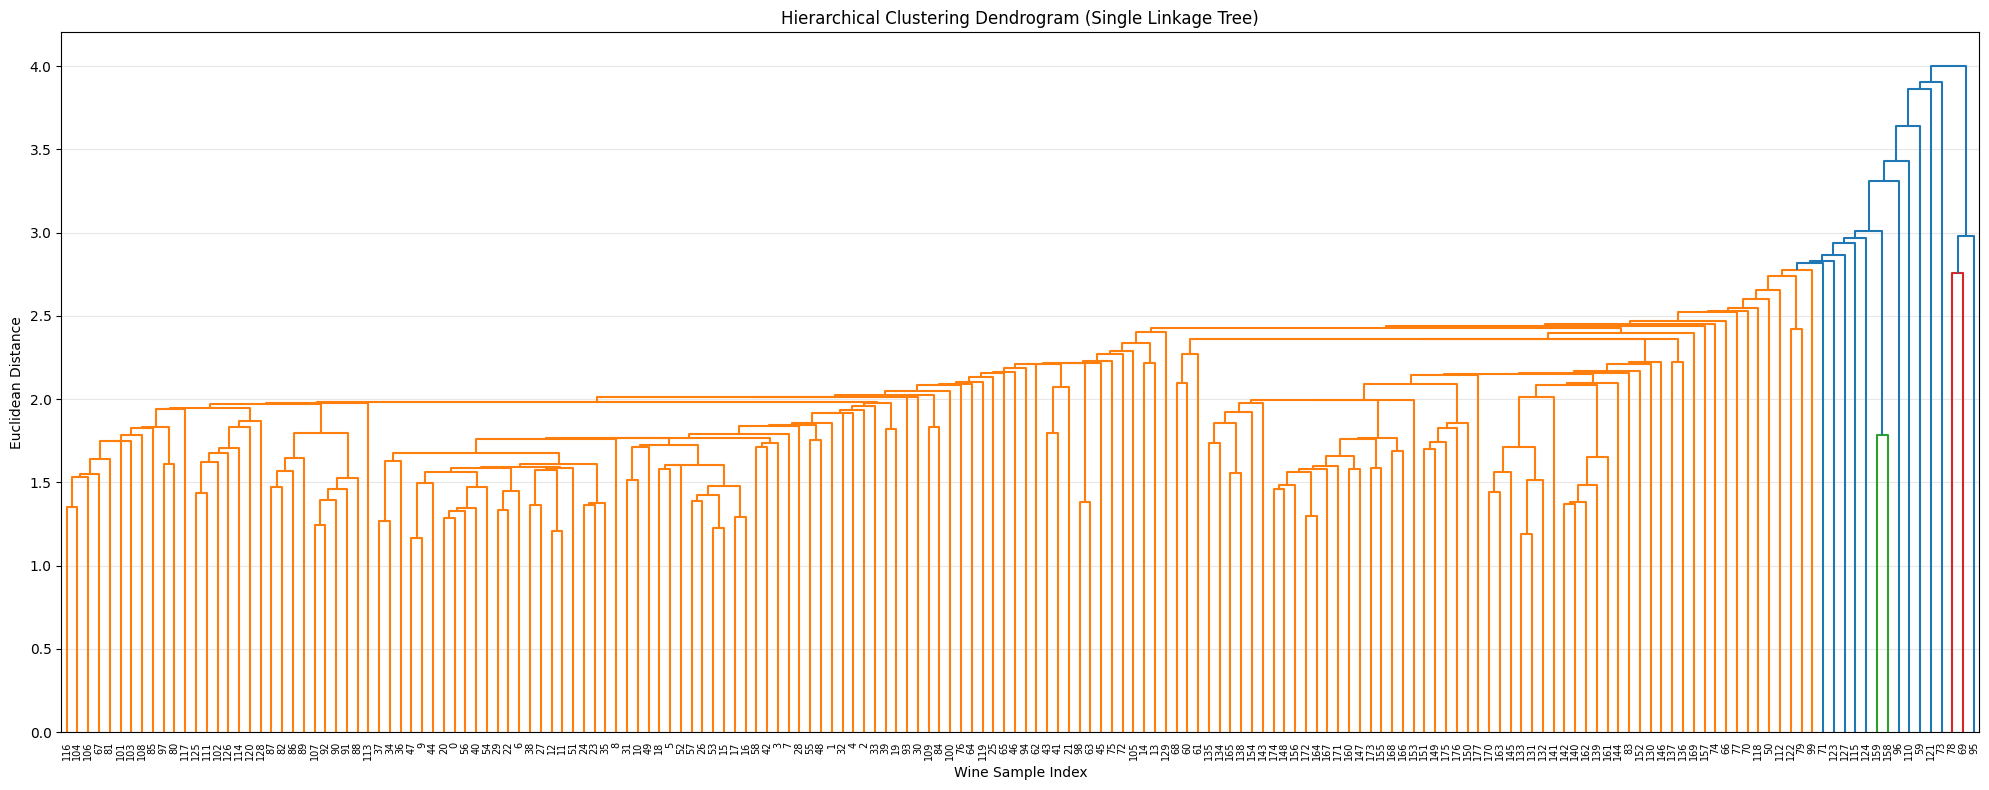

In [17]:
# Computes the single-linkage hierarchical clustering
linked = linkage(X_scaled, method='single', metric='euclidean')

# Plots the dendrogram
plt.figure(figsize=(20, 8))

dendrogram(
    linked,
    orientation='top',
    distance_sort='descending',
    leaf_rotation=90,
    leaf_font_size=7,
    color_threshold=0.7 * max(linked[:, 2])
)

plt.title('Hierarchical Clustering Dendrogram (Single Linkage Tree)')
plt.xlabel('Wine Sample Index')
plt.ylabel('Euclidean Distance')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Task 8:
* Treating the cluster assignments created by K-Means (k=3), DBSCAN, and HDBSCAN, as categorical feature representations. We can perform a stratified train/test split (80/20) on the Wine dataset.
>* For this experiment, a supervised classifier (Random Forest) is used to predict the wine cultivars.
>* The classification accuracy and Silhouette Scores are plotted for all three clustering algorithms.

K-Means Results:
Accuracy: 0.97
Silhouette Score: 0.28

DBSCAN Results:
Accuracy: 0.72
Silhouette Score: 0.22

HDBSCAN Results:
Accuracy: 0.72
Silhouette Score: 0.36


Final Evaluation Results:
  Algorithm  Classification Accuracy  Silhouette Score
0   K-Means                 0.972222          0.284859
1    DBSCAN                 0.722222          0.221661
2   HDBSCAN                 0.722222          0.360346


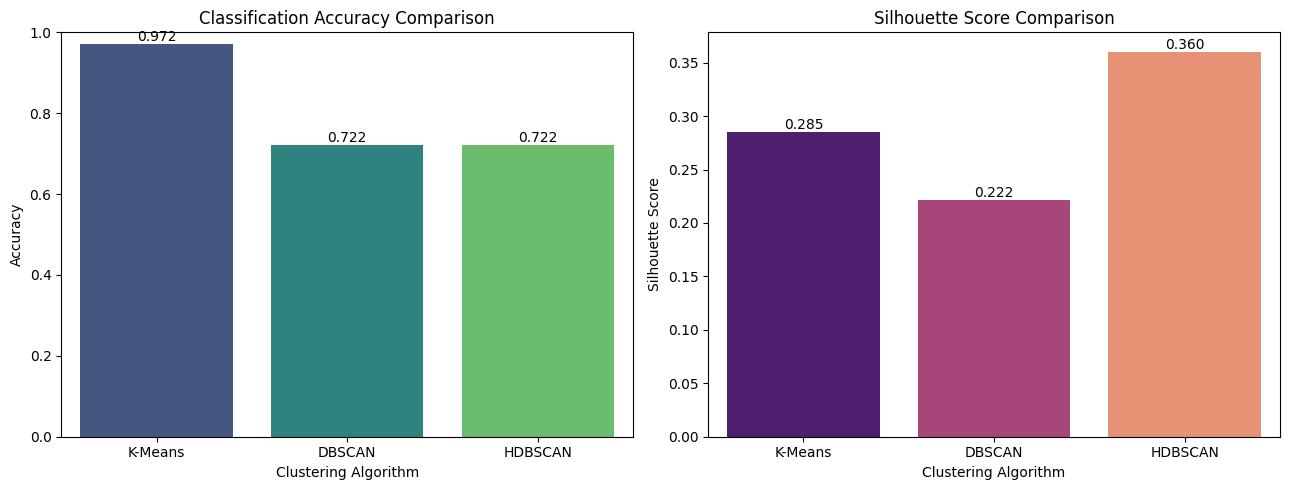

In [18]:
cluster_assignments = {
    'K-Means': kmeans_labels,
    'DBSCAN': dbscan_labels,
    'HDBSCAN': hdbscan_labels
}

accuracy_results = {}
silhouette_results = {}

indices = np.arange(len(y))

train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=42, stratify=y)

for algorithm, labels in cluster_assignments.items():
    print(f"{algorithm} Results:")
    cluster_features = pd.DataFrame({'Cluster': labels.astype(str)})

    X_train = cluster_features.iloc[train_idx]
    X_test = cluster_features.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    classifier = Pipeline([
        ('encoder', OneHotEncoder(handle_unknown='ignore')),
        ('model', RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'))
    ])

    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_results[algorithm] = accuracy

    valid_mask = labels != -1
    valid_labels = labels[valid_mask]
    valid_features = X_scaled[valid_mask]

    n_clusters = len(np.unique(valid_labels))

    if 2 <= n_clusters < len(valid_labels):
        sil_score = silhouette_score(valid_features, valid_labels)
    else:
        sil_score = np.nan

    silhouette_results[algorithm] = sil_score

    print(f"Accuracy: {accuracy:.2f}")
    print(f"Silhouette Score: {sil_score:.2f}")
    print()


# Creates the results DataFrame
results_df = pd.DataFrame({
    'Algorithm': list(cluster_assignments.keys()),
    'Classification Accuracy': [accuracy_results[a] for a in cluster_assignments],
    'Silhouette Score': [silhouette_results[a] for a in cluster_assignments]
})

print("\nFinal Evaluation Results:")
print(results_df)


# Plots classification accuracy and silhouette scores:

# Creates the side-by-side comparison plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Classification accuracy
sns.barplot(
    data=results_df,
    x='Algorithm',
    y='Classification Accuracy',
    hue='Algorithm',
    palette='viridis',
    legend=False,
    ax=axes[0]
)

axes[0].set_title('Classification Accuracy Comparison')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('Clustering Algorithm')
axes[0].set_ylim(0, 1)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.3f')

# Silhouette score
sns.barplot(
    data=results_df,
    x='Algorithm',
    y='Silhouette Score',
    hue='Algorithm',
    palette='magma',
    legend=False,
    ax=axes[1]
)

axes[1].set_title('Silhouette Score Comparison')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xlabel('Clustering Algorithm')

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.3f')

plt.tight_layout()
plt.show()
